# Electricity Classification: EDA and Preprocessing Pipeline
### OCTree reproduction · OpenML dataset 44156 · context-agnostic setting

This notebook loads the electricity dataset, prepares it exactly as the OCTree method needs
(Nam et al., 2024), and explores the training data.

**How the pipeline matches the paper**

| Requirement in the paper | Where it is done |
|---|---|
| Same dataset as the paper: OpenML **44156** (the cleaned, balanced electricity version from the Grinsztajn et al. (2022) benchmark) | Section 1.3 |
| 60 % train / 20 % validation / 20 % test, repeated over **three random splits** (seeds 0, 1, 2) | Section 2.4 |
| Context-agnostic setting: **ordinal-encode categoricals, min-max scale every feature, rename columns to `x1 … x8`** | Sections 2.3, 2.5, 2.6 |
| Prompt lists each column with its range, e.g. `x1 (Numerical value of 0.0 ~ 1.0)` (Appendix A) | Section 2.8 |
| Decision tree of depth 4 used as the feedback signal | Section 2.9 |

The pipeline starts from the authors' `preprocess.ipynb` (official OCTree repository). Every
difference from their code is marked **`[CHANGE]`** in the comments and listed in Section 2.11.

## 1. Importing Data

### 1.1 Environment Setup

This cell imports every library, records the software versions and defines a helper that fixes all
random seeds, so results can be reproduced.
Run `pip install pandas numpy scikit-learn seaborn matplotlib` if a library is missing.

In [1]:
# Standard library
import os          # file paths and folders
import sys         # Python version
import json        # saving metadata files
import random      # Python's own random generator (seeded below)

# Numbers, tables and charts
import numpy as np
import pandas as pd
import sklearn, matplotlib, seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loader, scaler and the decision tree used in the pipeline check
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix)


def seed_everything(seed: int = 42) -> None:
    # Fix every source of randomness so the same seed always gives the same result.
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

SEED = 42                  # general seed for charts and samples
seed_everything(SEED)

# Consistent chart style; show all table columns.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Record the environment so results are reproducible.
# [CHANGE] The authors used Python 3.8 and an older scikit-learn; newer versions read
#          OpenML files differently, so the versions are printed here.
print("Python    :", sys.version.split()[0])
print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("sklearn   :", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn   :", seaborn.__version__)

Python    : 3.13.16
numpy     : 2.1.3
pandas    : 2.2.3
sklearn   : 1.6.1
matplotlib: 3.10.0
seaborn   : 0.13.2


### 1.2 Configuration

All settings are kept in one place so the pipeline can be adjusted (for example, fewer seeds on a
slow computer) without changing the logic.

In [2]:
OPENML_ID   = 44156                # electricity dataset used in the OCTree paper
TARGET_COL  = "class"              # label column: price UP or DOWN
SEEDS       = [0, 1, 2]            # three random splits, as in the paper. Use [0] if compute is tight.
TRAIN_FRAC, VAL_FRAC = 0.6, 0.2    # 60 % train, 20 % validation, remaining 20 % test
OUTPUT_DIR  = "dataset"            # where the processed splits are written
CACHE_CSV   = os.path.join(OUTPUT_DIR, "electricity_raw.csv")   # offline copy of the raw data

os.makedirs(OUTPUT_DIR, exist_ok=True)    # [CHANGE] create the output folder automatically

### 1.3 Dataset Loading

The dataset is downloaded from OpenML once and then cached as a CSV file, so later runs work
offline and always use identical data.

**Which version of the electricity data?** OpenML has two versions:

* **151** is the original dataset (45,312 rows, in time order, about 58 % DOWN).
* **44156** is the version from the Grinsztajn et al. (2022) benchmark that the OCTree paper uses. It
  contains the same columns, but some DOWN rows were removed so UP and DOWN are exactly balanced, and
  the rows are stored in shuffled order. Day codes run from 0 to 6 instead of 1 to 7.

We use **44156** so our results can be compared directly with the paper.

In [3]:
if os.path.exists(CACHE_CSV):
    # Reuse the cached copy: faster, works offline, guarantees the same data every run.
    df = pd.read_csv(CACHE_CSV, dtype={"day": str})
    print(f"Loaded cached copy from {CACHE_CSV}")
else:
    # [CHANGE] parser="auto" set explicitly; the authors' default parser raised a FutureWarning.
    dataset = fetch_openml(data_id=OPENML_ID, as_frame=True, parser="auto")
    df = dataset.frame.copy()             # work on a copy so the downloaded data stays unchanged
    df.to_csv(CACHE_CSV, index=False)     # [CHANGE] cache for offline / repeatable runs
    print(f"Downloaded OpenML dataset {OPENML_ID} and cached it to {CACHE_CSV}")

# Standardise column names (remove spaces, lower case) for consistent use.
df.columns = df.columns.str.strip().str.lower()

display(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Downloaded OpenML dataset 44156 and cached it to dataset/electricity_raw.csv


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.898987,2,0.957447,0.068632,0.568283,0.004456,0.456499,0.644737,DOWN
1,0.867616,5,0.234043,0.033716,0.337102,0.001672,0.329622,0.846930,DOWN
2,0.009159,6,0.255319,0.059175,0.185808,0.003467,0.422915,0.414912,DOWN
3,0.898987,2,0.531915,0.087577,0.539572,0.004936,0.637752,0.491667,DOWN
4,0.868280,6,0.085106,0.027021,0.165129,0.001271,0.265924,0.748246,DOWN


Dataset shape: (38474, 9)
Columns: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer', 'class']


The dataset contains 38,474 observations, eight input features and one target column called
`class`.

The numerical features are supplied on normalised scales. Their values should not be read directly
as prices in currency units or electricity demand in megawatts (MW).

### 1.4 Data Dictionary

| Column | Meaning | Role |
|---|---|---|
| date | Normalised date indicator | Temporal input |
| day | Day-of-week code (0–6) | Categorical input |
| period | Normalised half-hour period within a day (48 periods) | Temporal input |
| nswprice | Normalised NSW electricity price | Numerical input |
| nswdemand | Normalised NSW electricity demand | Numerical input |
| vicprice | Normalised Victoria electricity price | Numerical input |
| vicdemand | Normalised Victoria electricity demand | Numerical input |
| transfer | Normalised scheduled transfer between states | Numerical input |
| class | NSW price label: UP or DOWN | Target |

The task classifies the current observation rather than predicting a future electricity price.
NSW price is included as an input and is closely related to how the UP or DOWN label is defined.
Therefore, the results should not be presented as evidence that the model can predict a future price
before it is observed.

These meanings are for our own understanding. In the context-agnostic setting the LLM never sees them;
it only sees the names `x1 … x8` (Section 2.6).

## 2. Preprocessing

### 2.1 Structural and Data-Quality Checks

We check the column names, data types, missing values, duplicate rows, day codes and target labels
before preparing the data. Repeated rows are counted but not removed, because repeated measurements
may be valid.

In [4]:
# List the expected inputs and target. Stop if anything is missing or unexpected.
expected_columns = ["date", "day", "period", "nswprice", "nswdemand",
                    "vicprice", "vicdemand", "transfer", "class"]
assert set(expected_columns) == set(df.columns), f"Unexpected columns: {df.columns.tolist()}"

# Stored data types and number of non-missing entries.
df.info()

# Missingness and number of distinct values per column.
quality = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing count": df.isna().sum(),
    "Missing percent": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique()
})
display(quality)

# Drop rows with missing values, as the authors did, and report how many were removed.
n_before = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Rows removed by dropna(): {n_before - len(df)}")

# Count identical rows without removing them.
print("Exact duplicate rows:", df.duplicated().sum())

# Day-of-week codes and their counts.
# [CHANGE] The authors printed these counts seven times in a loop that never used its
#          loop variable; we print them once.
print("\n'day' values and counts:")
print(df["day"].astype(str).value_counts().sort_index())

# Target labels, including any missing entries, and their shares.
print("\nTarget labels:")
print(df[TARGET_COL].value_counts(dropna=False))
print(df[TARGET_COL].value_counts(normalize=True).round(3))

display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38474 entries, 0 to 38473
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   date       38474 non-null  float64 
 1   day        38474 non-null  category
 2   period     38474 non-null  float64 
 3   nswprice   38474 non-null  float64 
 4   nswdemand  38474 non-null  float64 
 5   vicprice   38474 non-null  float64 
 6   vicdemand  38474 non-null  float64 
 7   transfer   38474 non-null  float64 
 8   class      38474 non-null  category
dtypes: category(2), float64(7)
memory usage: 2.1 MB


,Data type,Missing count,Missing percent,Unique values
date,float64,0,0.0,933
day,category,0,0.0,7
period,float64,0,0.0,48
nswprice,float64,0,0.0,4041
nswdemand,float64,0,0.0,5191
vicprice,float64,0,0.0,3764
vicdemand,float64,0,0.0,2799
transfer,float64,0,0.0,1858
class,category,0,0.0,2


Rows removed by dropna(): 0
Exact duplicate rows: 0

'day' values and counts:
day
0    5544
1    5605
2    5479
3    5463
4    5477
5    5453
6    5453
Name: count, dtype: int64

Target labels:
class
DOWN    19237
UP      19237
Name: count, dtype: int64
class
DOWN    0.5
UP      0.5
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
date,38474.0,0.498378,0.340142,0.0,0.031901,0.456263,0.880536,1.0
period,38474.0,0.506960,0.290737,0.0,0.255319,0.510638,0.765957,1.0
nswprice,38474.0,0.060176,0.042388,0.0,0.036268,0.051189,0.075868,1.0
nswdemand,38474.0,0.434220,0.162010,0.0,0.321333,0.452246,0.542101,1.0
vicprice,38474.0,0.003568,0.010905,0.0,0.002360,0.003467,0.003467,1.0
vicdemand,38474.0,0.427452,0.121001,0.0,0.382444,0.422915,0.477991,1.0
transfer,38474.0,0.497235,0.152075,0.0,0.414912,0.414912,0.599123,1.0


The dataset has no missing values and 0 exact duplicate rows. UP and DOWN are exactly
balanced, because this benchmark version was balanced by its curators. The `day` column contains
category codes 0–6, so it is treated as a category rather than a measurement.

### 2.2 Validate Types, Labels and Time Information

We make sure the measurement columns contain numbers and that the target labels are consistently
written as UP or DOWN.

In dataset 44156 the rows are shuffled and some rows were removed, so the original row order cannot
be used as a time sequence. Instead we check that the time columns are valid (48 half-hour periods,
day codes 0–6) and build a **time order** by sorting on `date` and then `period`. This order is used
only for the time-based charts (Sections 3.1b and 3.11) and the optional time-ordered split
(Section 2.7), never as a model input.

In [5]:
# Separate numerical measurements from the day-of-week category.
numeric_features = ["date", "period", "nswprice", "nswdemand",
                    "vicprice", "vicdemand", "transfer"]
categorical_features = ["day"]

# Numerical columns must contain numbers; raise an error otherwise.
for column in numeric_features:
    df[column] = pd.to_numeric(df[column], errors="raise")

# Store day codes as strings (categories) and clean the target labels.
df["day"] = df["day"].astype(str).str.strip()
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip().str.upper()

# Missing or unexpected targets must be investigated before proceeding.
assert df[TARGET_COL].notna().all()
assert set(df[TARGET_COL].unique()) == {"DOWN", "UP"}

# Day codes must be 0..6.
assert set(df["day"].unique()) <= {str(i) for i in range(7)}, "Unexpected day code."

# Period values must be one of the 48 half-hour slots: 0/47, 1/47, ..., 47/47.
slot = df["period"] * 47
assert np.allclose(slot, slot.round(), atol=1e-4), "Period values need investigation."

# Time order: sort by date, then by half-hour period.
# [CHANGE] The original (151) version was already in time order; 44156 is shuffled, so the
#          order is rebuilt here. 'time_rank' 0 is the earliest observation.
df["time_rank"] = df.sort_values(["date", "period"], kind="stable").index.argsort()

# How well 'date' marks a single day: count dates that cover more than one day code.
days_per_date = df.groupby("date")["day"].nunique()
print(f"Distinct date values: {len(days_per_date)}; "
      f"dates covering two day codes: {(days_per_date > 1).sum()}")
print("Type, label and time checks passed.")

Distinct date values: 933; dates covering two day codes: 11
Type, label and time checks passed.


All checks passed. Each `date` value corresponds to one observed day in almost every case; a small
number of `date` values cover two day codes in the source data. The time order is therefore
approximate, and it has gaps where DOWN rows were removed during balancing. It is good enough for
charts and a robustness check, but it does not confirm exact calendar dates.

### 2.3 Encode the Target and Separate Inputs

* **Target:** DOWN = 0, UP = 1 (the authors' mapping).
* **Categorical feature `day`:** the paper's context-agnostic setting uses **ordinal encoding** of
  categorical features. Because the categories are already the digits 0–6, ordinal encoding simply
  means converting the text to integers.

X contains the eight input features in the original column order, and y contains the target.
Neither the original class column nor the encoded target is included in X, because that would give
the model the answer.

In [6]:
# Convert the class labels into numbers: DOWN -> 0, UP -> 1.
df["target"] = df[TARGET_COL].map({"DOWN": 0, "UP": 1}).astype(int)

# The eight inputs, in the original column order (this order defines x1 ... x8 later).
feature_names = [c for c in expected_columns if c != TARGET_COL]
X_df = df[feature_names].copy()

# [CHANGE] Explicit ordinal encoding of 'day' (text '0'..'6' -> integer 0..6).
#          The authors relied on a hidden text-to-number conversion inside MinMaxScaler.
X_df["day"] = X_df["day"].astype(int)

# Every feature is now numeric -> a plain grid of numbers for the scaler and models.
X = X_df.to_numpy(dtype=np.float64)
y = df["target"].to_numpy(dtype=np.int8)

# The answer must not be among the inputs, and every row needs an answer.
assert "class" not in X_df.columns and "target" not in X_df.columns
assert set(np.unique(y)) == {0, 1}
assert len(X) == len(y)

print("X shape:", X.shape, "| y shape:", y.shape, "| labels:", sorted(set(y.tolist())))
display(df[["class", "target"]].head())

X shape: (38474, 8) | y shape: (38474,) | labels: [0, 1]


,class,target
0,DOWN,0
1,DOWN,0
2,DOWN,0
3,DOWN,0
4,DOWN,0


### 2.4 Training, Validation and Test Splits (three random seeds)

OCTree uses the three groups for different jobs, so keeping them separate is essential:

* **Training (60 %)** fits the prediction model *and* the decision tree whose text is fed back to the LLM.
* **Validation (20 %)** scores each rule the LLM proposes; the best rule is chosen on this score.
* **Test (20 %)** is used **once**, at the very end, to report the final result.

Because the best rule is *selected* using validation scores over many rounds, the test set is the
only unbiased estimate of performance. We also verify that no row appears in two groups.

**Why random and not time-ordered?** The paper uses random splits, and we follow it so our results
are comparable with theirs. Neighbouring half-hours are strongly related, so random splitting can
make scores look better than they would be on genuinely new days.

In [7]:
def split_indices(n_rows: int, seed: int):
    # Random 60/20/20 split, identical to the authors' permutation logic.
    seed_everything(seed)
    perm = np.random.permutation(n_rows)                      # shuffle all row positions
    n_train = int(n_rows * TRAIN_FRAC)
    n_val   = int(n_rows * (TRAIN_FRAC + VAL_FRAC))
    return perm[:n_train], perm[n_train:n_val], perm[n_val:]

splits = {}   # keeps every split in memory for the later steps
for seed in SEEDS:
    tr_idx, va_idx, te_idx = split_indices(len(X), seed)

    # Safety check: the groups must not share any row, and every row must be used.
    assert not (set(tr_idx) & set(va_idx)) and not (set(tr_idx) & set(te_idx)) \
        and not (set(va_idx) & set(te_idx)), "Overlap between splits!"
    assert len(tr_idx) + len(va_idx) + len(te_idx) == len(X)

    splits[seed] = dict(xtrain=X[tr_idx], xval=X[va_idx], xtest=X[te_idx],
                        ytrain=y[tr_idx], yval=y[va_idx], ytest=y[te_idx],
                        idx=dict(train=tr_idx, val=va_idx, test=te_idx))
    print(f"seed {seed}: train={len(tr_idx)} | val={len(va_idx)} | test={len(te_idx)} "
          f"| train UP share={y[tr_idx].mean():.3f}")

# Readable training rows (original values and labels) for the EDA in Section 3.
# Only seed-0 TRAINING rows are explored; validation and test stay unseen.
eda = df.iloc[splits[SEEDS[0]]["idx"]["train"]].copy()

seed 0: train=23084 | val=7695 | test=7695 | train UP share=0.502
seed 1: train=23084 | val=7695 | test=7695 | train UP share=0.497
seed 2: train=23084 | val=7695 | test=7695 | train UP share=0.502


Each seed gives 23,084 training, 7,695 validation and 7,695 test observations. The groups do
not overlap, and each keeps roughly the same UP/DOWN balance. Detailed EDA uses only the seed-0
training group.

### 2.5 Min-Max Normalisation (fitted on training data only)

The paper scales every feature to the range **[0, 1]**:

$$x' = \frac{x - \min_{\text{train}}(x)}{\max_{\text{train}}(x) - \min_{\text{train}}(x)}$$

The scaler learns each column's minimum and maximum from the **training** rows only and applies the
same mapping to validation and test, so no information from those groups leaks into training.
Validation and test values can therefore fall slightly outside [0, 1]; that is expected.

Tree models do not need scaling, but OCTree does it for two reasons: it hides the real units, which is
part of the context-agnostic setting, and it puts every column on the same 0–1 range, so arithmetic
rules the LLM writes (such as `x4 * x3`) combine comparable values.

In [8]:
for seed, s in splits.items():
    scaler = MinMaxScaler()
    scaler.fit(s["xtrain"])                        # learn min/max from TRAINING only
    for part in ("xtrain", "xval", "xtest"):
        s[part] = scaler.transform(s[part])        # apply the same mapping to all three groups
    s["scaler_min"], s["scaler_max"] = scaler.data_min_, scaler.data_max_   # kept for metadata

# [CHANGE] The authors' code had two extra cells after this loop that scaled the last seed's
#          already-scaled data a second time and saved it outside the seed folders. They were
#          leftovers, so they were removed; each split is scaled exactly once.

# Check the result on seed 0.
s0 = splits[SEEDS[0]]
print("Training range per column (should be exactly 0 and 1):")
print(np.round(s0["xtrain"].min(axis=0), 3), np.round(s0["xtrain"].max(axis=0), 3))
print("Validation range per column (may go slightly outside 0-1):")
print(np.round(s0["xval"].min(axis=0), 3), np.round(s0["xval"].max(axis=0), 3))

# Every group must be complete and free of missing or infinite values.
checks = []
for seed, s in splits.items():
    for name in ("train", "val", "test"):
        xs, ys = s["x" + name], s["y" + name]
        assert xs.shape[0] == len(ys) and xs.shape[1] == len(feature_names)
        assert np.isfinite(xs).all()
        checks.append({"Seed": seed, "Split": name, "Rows": xs.shape[0], "Features": xs.shape[1],
                       "Missing": int(np.isnan(xs).sum()), "Infinite": int(np.isinf(xs).sum())})
display(pd.DataFrame(checks))
print("All preprocessing checks passed.")

Training range per column (should be exactly 0 and 1):
[0. 0. 0. 0. 0. 0. 0. 0.] [1. 1. 1. 1. 1. 1. 1. 1.]
Validation range per column (may go slightly outside 0-1):
[ 0.     0.     0.     0.     0.002  0.    -0.006  0.006] [1.    1.    1.    0.98  1.02  0.984 0.983 0.986]


,Seed,Split,Rows,Features,Missing,Infinite
0,0,train,23084,8,0,0
1,0,val,7695,8,0,0
2,0,test,7695,8,0,0
3,1,train,23084,8,0,0
4,1,val,7695,8,0,0
5,1,test,7695,8,0,0
6,2,train,23084,8,0,0
7,2,val,7695,8,0,0
8,2,test,7695,8,0,0


All preprocessing checks passed.


### 2.6 Anonymise Column Names (context-agnostic setting)

In the context-agnostic setting the LLM must not know what the columns mean, so the real names are
replaced with `x1 … x8`. The mapping is kept privately for our own analysis and is **never** put into
an LLM prompt. Hiding the names also makes it harder for the LLM to recognise this well-known public
dataset and recall facts about it instead of using the feedback it receives.

In [9]:
anon_names = [f"x{i + 1}" for i in range(len(feature_names))]   # x1 ... x8
name_map   = dict(zip(anon_names, feature_names))               # PRIVATE: for our analysis only

# [CHANGE] The authors' preprocessing notebook kept the original names; the renaming happened
#          elsewhere in their code. It is done here so the data is ready for the prompts.
pd.DataFrame({"anonymous name": anon_names, "original name (hidden from LLM)": feature_names})

,anonymous name,original name (hidden from LLM)
0,x1,date
1,x2,day
2,x3,period
3,x4,nswprice
4,x5,nswdemand
5,x6,vicprice
6,x7,vicdemand
7,x8,transfer


### 2.7 Save the Processed Splits

Each seed gets its own folder with the same file names as the authors, so the official OCTree code can
read them. The `0` in `xtrain0.npy` means *round 0*: the original features before any LLM-generated
column is added. A `metadata.json` file records how each split was made.


In [10]:
for seed, s in splits.items():
    seed_dir = os.path.join(OUTPUT_DIR, f"seed{seed}")
    os.makedirs(seed_dir, exist_ok=True)                    # [CHANGE] create folders automatically
    for part in ("xtrain", "xval", "xtest"):
        np.save(os.path.join(seed_dir, f"{part}0.npy"), s[part])
    for part in ("ytrain", "yval", "ytest"):
        np.save(os.path.join(seed_dir, f"{part}.npy"), s[part])

    # [CHANGE] A small metadata file per seed so every run is traceable.
    meta = {
        "openml_id": OPENML_ID, "seed": seed, "split": "random 60/20/20",
        "n_train": int(len(s["ytrain"])), "n_val": int(len(s["yval"])), "n_test": int(len(s["ytest"])),
        "anonymous_columns": anon_names,
        "original_columns_private": feature_names,
        "train_min_before_scaling": s["scaler_min"].tolist(),
        "train_max_before_scaling": s["scaler_max"].tolist(),
    }
    with open(os.path.join(seed_dir, "metadata.json"), "w") as f:
        json.dump(meta, f, indent=2)

print("\nSaved files:")
for root, _, files in sorted(os.walk(OUTPUT_DIR)):
    if files and root != OUTPUT_DIR:
        print(" ", root, "->", sorted(files))


Saved files:
  dataset/seed0 -> ['metadata.json', 'xtest0.npy', 'xtrain0.npy', 'xval0.npy', 'ytest.npy', 'ytrain.npy', 'yval.npy']
  dataset/seed1 -> ['metadata.json', 'xtest0.npy', 'xtrain0.npy', 'xval0.npy', 'ytest.npy', 'ytrain.npy', 'yval.npy']
  dataset/seed2 -> ['metadata.json', 'xtest0.npy', 'xtrain0.npy', 'xval0.npy', 'ytest.npy', 'ytrain.npy', 'yval.npy']


### 2.8 Turn the Table into Text the LLM Can Read

Tabular data has no images to resize or sentences to tokenise. The equivalent step in OCTree is
**serialising the table's structure into the prompt**: Appendix A of the paper shows that every prompt
starts by listing each column with its type and range, for example
`- x1 (Numerical value of 0.0 ~ 1.0)`. We build that block from the *training* data. The actual
tokenisation is done by the LLM itself when it reads the prompt.

Because every column was scaled to 0–1, every line shows the same range. That is expected in the
context-agnostic setting: the LLM learns what matters from the feedback (scores and decision trees),
not from the column descriptions.

In [11]:
def describe_columns(x_train: np.ndarray, names: list) -> str:
    '''One line per column in the format used by the OCTree prompts (Appendix A).'''
    lines = []
    for j, name in enumerate(names):
        lo, hi = x_train[:, j].min(), x_train[:, j].max()     # range in the training data
        lines.append(f"- {name} (Numerical value of {lo:.1f} ~ {hi:.1f})")
    return "\n".join(lines)

column_block = describe_columns(splits[SEEDS[0]]["xtrain"], anon_names)
print(column_block)

- x1 (Numerical value of 0.0 ~ 1.0)
- x2 (Numerical value of 0.0 ~ 1.0)
- x3 (Numerical value of 0.0 ~ 1.0)
- x4 (Numerical value of 0.0 ~ 1.0)
- x5 (Numerical value of 0.0 ~ 1.0)
- x6 (Numerical value of 0.0 ~ 1.0)
- x7 (Numerical value of 0.0 ~ 1.0)
- x8 (Numerical value of 0.0 ~ 1.0)


### 2.9 Pipeline Check: Baseline Decision Tree

OCTree uses a decision tree (CART, maximum depth 4) as its feedback signal, so we confirm that the
processed data feeds such a tree, and print the tree in the if-else text form the LLM will read.
This is a pipeline check, not a final result. The tree is fitted on seed-0 training data and scored on
validation data only; the test data stays untouched.

In [12]:
s = splits[SEEDS[0]]
tree = DecisionTreeClassifier(max_depth=4, random_state=SEED)
tree.fit(s["xtrain"], s["ytrain"])

pred  = tree.predict(s["xval"])
proba = tree.predict_proba(s["xval"])[:, 1]
print("Validation accuracy         :", round(accuracy_score(s["yval"], pred), 4))
print("Validation F1 (UP)          :", round(f1_score(s["yval"], pred), 4))
print("Validation balanced accuracy:", round(balanced_accuracy_score(s["yval"], pred), 4))
print("Validation ROC-AUC          :", round(roc_auc_score(s["yval"], proba), 4))
print("Confusion matrix (rows = true DOWN/UP, cols = predicted DOWN/UP):")
print(confusion_matrix(s["yval"], pred))

# The decision tree as if-else text, using only the anonymous names (what OCTree feeds the LLM).
print("\nDecision tree reasoning (as shown to the LLM):")
print(export_text(tree, feature_names=anon_names, decimals=3))

Validation accuracy         : 0.729
Validation F1 (UP)          : 0.6647
Validation balanced accuracy: 0.7281
Validation ROC-AUC          : 0.8293
Confusion matrix (rows = true DOWN/UP, cols = predicted DOWN/UP):
[[3543  324]
 [1761 2067]]

Decision tree reasoning (as shown to the LLM):
|--- x4 <= 0.068
|   |--- x5 <= 0.275
|   |   |--- x4 <= 0.059
|   |   |   |--- x3 <= 0.309
|   |   |   |   |--- class: 0
|   |   |   |--- x3 >  0.309
|   |   |   |   |--- class: 0
|   |   |--- x4 >  0.059
|   |   |   |--- x4 <= 0.062
|   |   |   |   |--- class: 1
|   |   |   |--- x4 >  0.062
|   |   |   |   |--- class: 0
|   |--- x5 >  0.275
|   |   |--- x1 <= 0.434
|   |   |   |--- x4 <= 0.056
|   |   |   |   |--- class: 0
|   |   |   |--- x4 >  0.056
|   |   |   |   |--- class: 0
|   |   |--- x1 >  0.434
|   |   |   |--- x1 <= 0.885
|   |   |   |   |--- class: 0
|   |   |   |--- x1 >  0.885
|   |   |   |   |--- class: 0
|--- x4 >  0.068
|   |--- x4 <= 0.078
|   |   |--- x3 <= 0.245
|   |   |   |--- x

### 2.10 Preprocessing Decisions and Applicability

The assignment lists resizing, normalisation, augmentation and tokenisation as examples. We apply the
steps that fit this tabular dataset and the OCTree method.

| Step | Decision | Reason |
|---|---|---|
| Resizing | Not applicable | The inputs are table columns, not images. |
| Normalisation / scaling | Min-max to [0, 1], fitted on training data only | Required by the paper's context-agnostic setting; hides units and puts every column on the same range for LLM-written rules. |
| Augmentation | Not used | OCTree adds new *columns* (features), not synthetic rows. |
| Tokenisation | Replaced by prompt serialisation (Section 2.8) | Tabular equivalent: columns are described as text for the LLM, which tokenises the prompt itself. |
| Missing values | Rows with missing values dropped (none found) | Same as the authors; no imputation needed. |
| Encoding of `day` | Ordinal (0–6) | The paper's context-agnostic setting uses ordinal encoding; keeps exactly eight columns `x1 … x8`. |
| Column names | Anonymised to `x1 … x8` | Required by the context-agnostic setting. |
| Split | Random 60/20/20 × 3 seeds| All scaling settings are learned from training data only and reused for validation and test data.

### 2.11 Dataset Loading and Environment Adaptations

**Changes from the authors' `preprocess.ipynb`**

| # | Authors' code | This notebook | Reason |
|---|---|---|---|
| 1 | `fetch_openml(data_id=44156)` with the default parser (raised a FutureWarning) | `parser="auto"` | Same result on current scikit-learn versions |
| 2 | Downloaded on every run | Cached as a local CSV | Works offline; identical data every run |
| 3 | `seed0/`, `seed1/` … folders had to exist already | Folders created automatically | `np.save` fails on missing folders |
| 4 | Loop printed the `day` counts seven times (unused loop variable) | Printed once | Removed leftover debug code |
| 5 | Mixed text/number array passed to the scaler | Explicit ordinal encoding of `day` | Makes the encoding visible and type-safe |
| 6 | Two extra cells re-scaled already-scaled data and saved it outside the seed folders | Removed | Each split scaled exactly once |
| 7 | Original column names kept | Renamed to `x1 … x8`, mapping kept privately | Context-agnostic setting |
| 8 | No metadata | `metadata.json` per split | Traceability |
| 9 | — | Prompt column block (2.8), decision tree check (2.9), comparison with authors' files and time-ordered split (2.7) | Prepares the OCTree loop and checks the pipeline |

**Kept identical to the authors:** dataset 44156, `dropna()`, DOWN → 0 / UP → 1, the
`np.random.permutation` 60/20/20 split for seeds 0, 1, 2, min-max scaling fitted on training data only,
and the output file names.

**Other adaptations:** column names stripped and lower-cased; data quality, label and time checks added
as assertions; EDA uses readable original values from the seed-0 training rows only.

## 3. Exploratory Data Analysis

We explore the seed-0 training data using tables and charts. Validation and test data are reserved for
later evaluation. The charts use the original (unscaled) values and readable UP and DOWN labels.

### 3.1 Summary Statistics and Feature Ranges

We check the average, spread, minimum and maximum of each numerical feature, and count any values
outside the supplied 0–1 range.

In [13]:
print("Training observations used for EDA:", len(eda))

display(eda[numeric_features].describe().round(4))

range_summary = pd.DataFrame({
    "Minimum": eda[numeric_features].min(),
    "Maximum": eda[numeric_features].max(),
    "Below zero": (eda[numeric_features] < 0).sum(),
    "Above one": (eda[numeric_features] > 1).sum()
})
display(range_summary)

Training observations used for EDA: 23084


,date,period,nswprice,nswdemand,vicprice,vicdemand,transfer
count,23084.0000,23084.0000,23084.0000,23084.0000,23084.0000,23084.0000,23084.0000
mean,0.4993,0.5091,0.0605,0.4347,0.0035,0.4272,0.4976
std,0.3399,0.2901,0.0436,0.1619,0.0097,0.1215,0.1520
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0295,0.0000
25%,0.0319,0.2766,0.0360,0.3221,0.0023,0.3806,0.4149
50%,0.4564,0.5106,0.0512,0.4522,0.0035,0.4229,0.4149
75%,0.8805,0.7660,0.0763,0.5424,0.0035,0.4772,0.5996
max,1.0000,1.0000,1.0000,0.9808,0.9962,1.0000,0.9592


,Minimum,Maximum,Below zero,Above one
date,0.000000,1.000000,0,0
period,0.000000,1.000000,0,0
nswprice,0.000000,1.000000,0,0
nswdemand,0.000000,0.980809,0,0
vicprice,0.000000,0.996228,0,0
vicdemand,0.029518,1.000000,0,0
transfer,0.000000,0.959211,0,0


These tables describe the numerical features in the training data. Because the training rows are a
random 60 % sample of the whole dataset, most features reach close to their full 0–1 range.

The values are normalised and cannot be read directly as prices in currency units or demand in
megawatts. A transfer value of 0.5 does not necessarily mean zero electricity transfer.

### 3.1b Raw Data Examples

The table shows raw training records. The plot shows NSW price and demand over the first 200 training
observations in **time order** (sorted by date and period), shaded by the UP/DOWN label. Because the
training set is a random sample and some DOWN rows were removed in this dataset version, consecutive
points are close in time but not always exactly one half-hour apart.

,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class,target
20464,0.008938,1,0.021277,0.099616,0.536447,0.003467,0.422915,0.414912,UP,1
15324,0.898810,5,0.063830,0.055572,0.413716,0.003400,0.470482,0.645175,DOWN,0
27104,0.442812,4,0.340426,0.068842,0.551622,0.004771,0.551787,0.341667,UP,1
37728,0.908013,4,0.255319,0.136153,0.429188,0.009271,0.621958,0.337719,UP,1
23852,0.031193,3,0.319149,0.125465,0.479917,0.003467,0.422915,0.414912,UP,1
37489,0.907438,5,1.000000,0.080611,0.452990,0.005617,0.470223,0.377632,UP,1
7999,0.885978,0,0.936170,0.029242,0.398393,0.001863,0.331952,0.809649,DOWN,0
21014,0.013318,3,0.936170,0.090068,0.623624,0.003467,0.422915,0.414912,UP,1
2612,0.906774,4,0.212766,0.034316,0.181196,0.002270,0.118591,0.669737,DOWN,0
23177,0.026857,3,0.765957,0.108502,0.505356,0.003467,0.422915,0.414912,UP,1


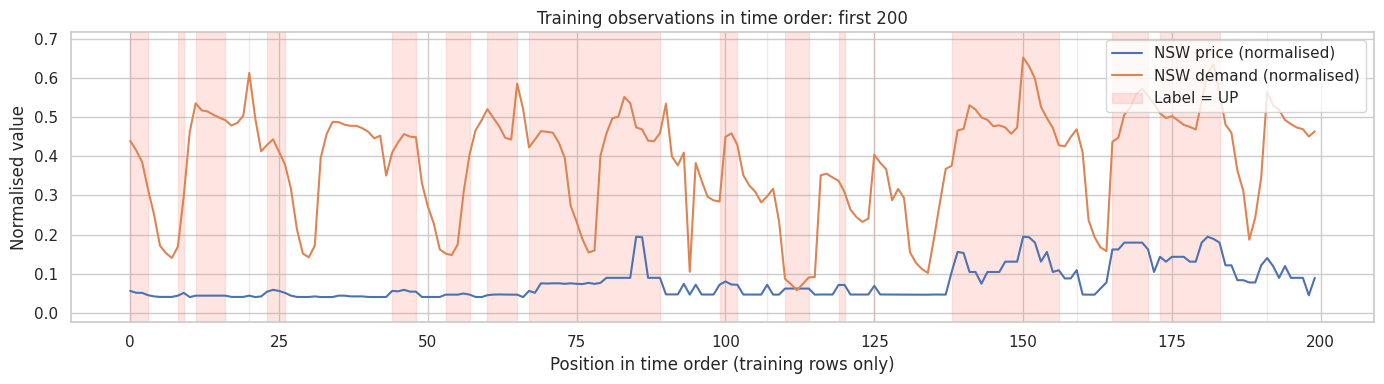

In [14]:
display(eda.drop(columns="time_rank").head(10))

# First 200 training observations in time order.
raw = eda.sort_values("time_rank").head(200).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(raw.index, raw["nswprice"], label="NSW price (normalised)")
ax.plot(raw.index, raw["nswdemand"], label="NSW demand (normalised)")

# Shade the background where the label is UP.
up = raw["class"] == "UP"
ax.fill_between(raw.index, 0, 1, where=up.values, color="salmon",
                alpha=0.2, transform=ax.get_xaxis_transform(), label="Label = UP")

ax.set_title("Training observations in time order: first 200")
ax.set_xlabel("Position in time order (training rows only)")
ax.set_ylabel("Normalised value")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 3.2 Target-Class Distribution

We count the UP and DOWN labels in the training data. This shows whether one class is more common and
gives a simple accuracy reference: always predicting the most common class.

,Count,Percent
class,,
DOWN,11503,49.83
UP,11581,50.17


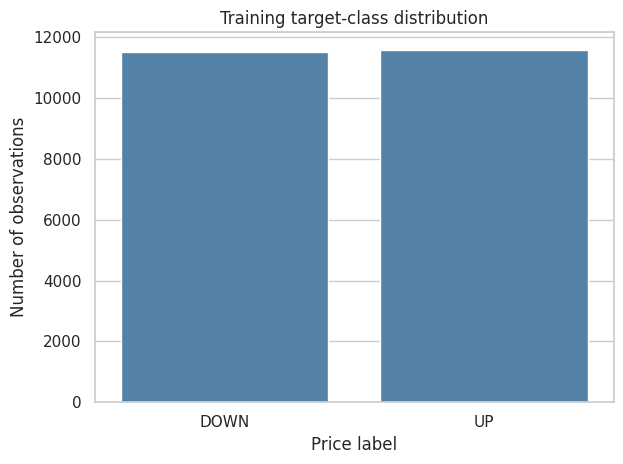

Majority class: UP
Majority-class training accuracy: 50.17%


In [15]:
class_summary = (eda["class"].value_counts()
                 .reindex(["DOWN", "UP"], fill_value=0)
                 .to_frame("Count"))
class_summary["Percent"] = (class_summary["Count"] / len(eda) * 100).round(2)
display(class_summary)

sns.countplot(data=eda, x="class", order=["DOWN", "UP"], color="steelblue")
plt.title("Training target-class distribution")
plt.xlabel("Price label")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

# Simple reference: always predict the majority class (training accuracy, not a model result).
majority = class_summary["Count"].idxmax()
share = class_summary.loc[majority, "Percent"]
print(f"Majority class: {majority}")
print(f"Majority-class training accuracy: {share:.2f}%")

The training data contains 11,503 DOWN observations (49.83 %) and 11,581 UP
observations (50.17 %). The classes are almost exactly balanced, so always predicting one class
scores only about 50 %, and accuracy (or error rate, as reported in the paper) is a fair main metric.

### 3.2b Class Balance in Training and Validation

We compare class counts in training and validation to check whether label frequencies differ. Test
labels are reserved for the final evaluation.

In [16]:
s = splits[SEEDS[0]]
rows = []
for name, labels in [("Training", s["ytrain"]), ("Validation", s["yval"])]:
    rows.append({"Split": name, "Rows": len(labels),
                 "DOWN": int((labels == 0).sum()), "UP": int((labels == 1).sum()),
                 "UP %": round(labels.mean() * 100, 2)})
display(pd.DataFrame(rows))

# Constant baseline chosen from training labels only, scored on validation.
majority_label = int(s["ytrain"].mean() >= 0.5)
validation_baseline = (s["yval"] == majority_label).mean() * 100
print(f"Training-majority baseline on validation: {validation_baseline:.2f}% accuracy")
# No test score is calculated until the final evaluation.

,Split,Rows,DOWN,UP,UP %
0,Training,23084,11503,11581,50.17
1,Validation,7695,3867,3828,49.75


Training-majority baseline on validation: 49.75% accuracy


Training and validation have nearly the same share of UP labels (validation: 49.75 %), as
expected from a random split of a balanced dataset. Validation model scores should be compared with
the training-majority baseline above.

### 3.3 Numerical Feature Distributions

Histograms group numerical values into ranges and count how many observations fall into each range.
They help us see where values are concentrated, whether the distribution is uneven, and whether some
values are unusual.

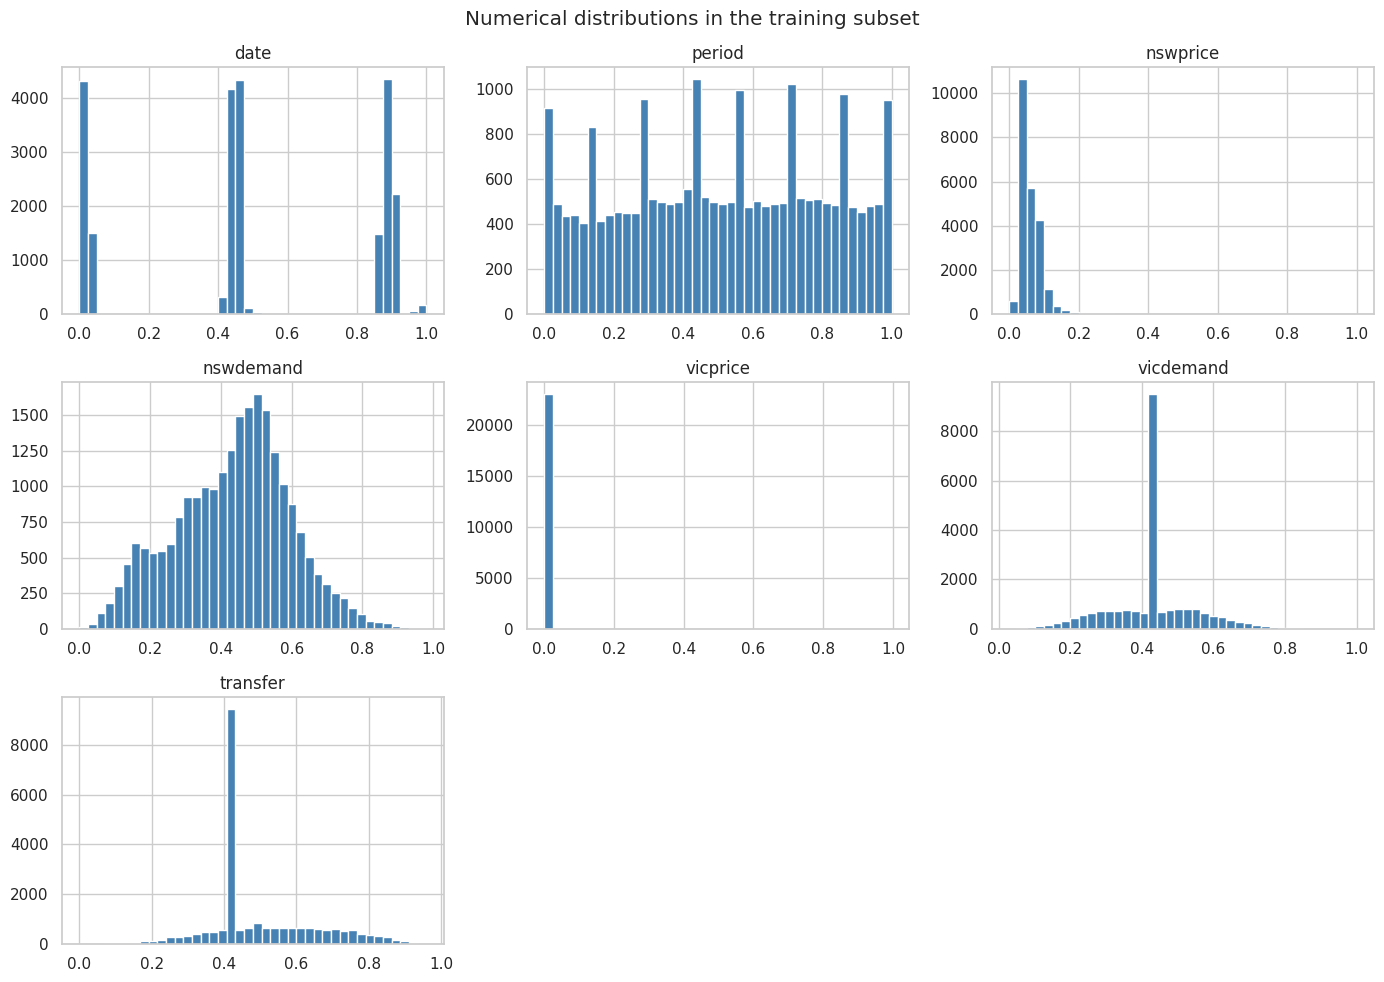

In [17]:
eda[numeric_features].hist(bins=40, figsize=(14, 10), color="steelblue", edgecolor="white")
plt.suptitle("Numerical distributions in the training subset")
plt.tight_layout()
plt.show()

Each feature has its own distribution. Normalising values changes their scale but does not make their
distributions symmetrical or remove unusual values. Repeated values or sharp peaks may need further
investigation, but they are not automatically evidence of measurement errors.

### 3.4 Box Plots and Unusual Observations

Box plots show the median and the middle 50 % of values. Points beyond the whiskers flag values that
are far from the main group and may need checking.

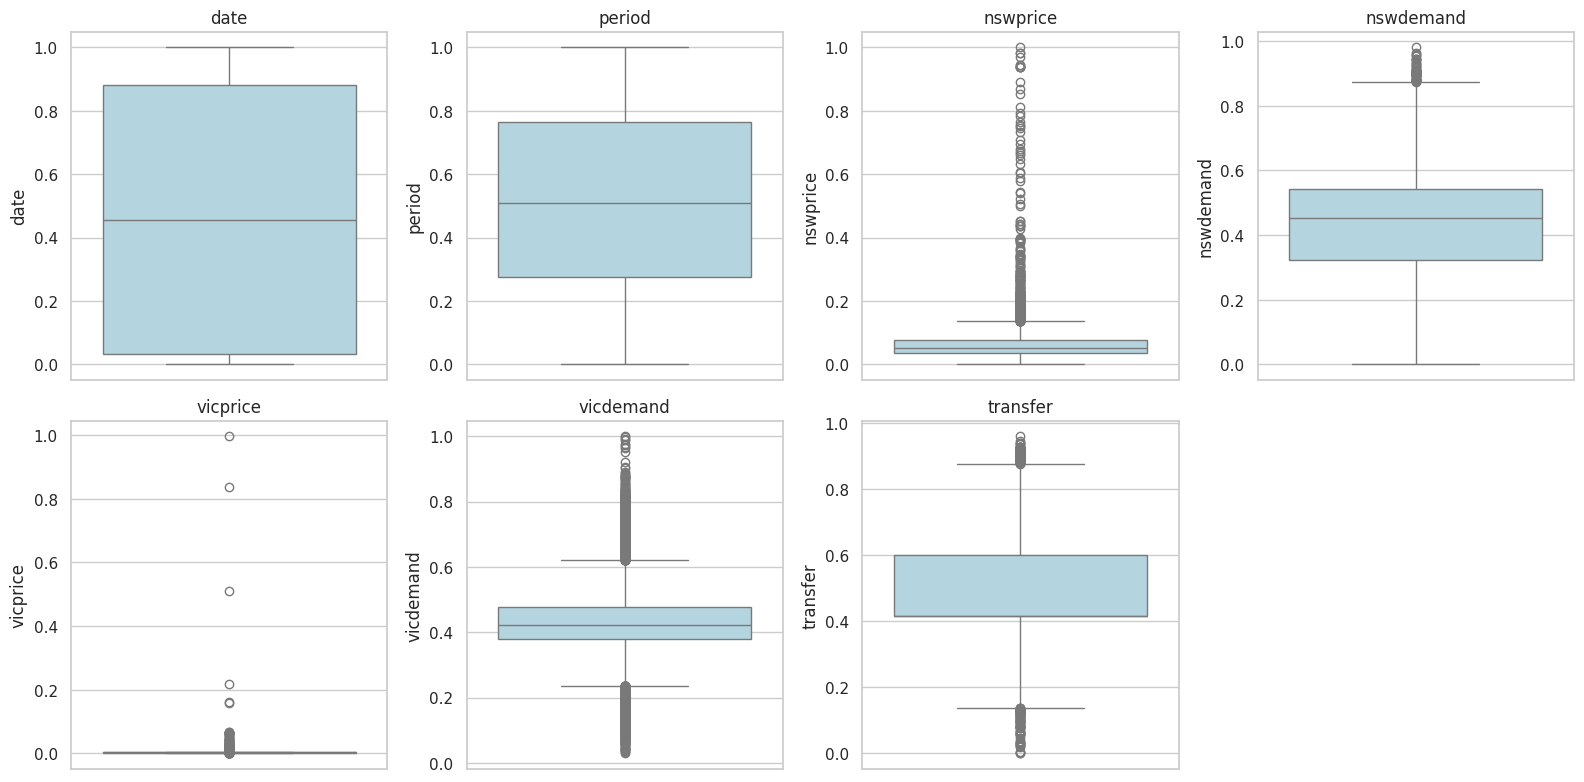

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, numeric_features):
    sns.boxplot(data=eda, y=column, ax=ax, color="lightblue")
    ax.set_title(column)
axes.flat[-1].axis("off")     # hide the unused eighth position
plt.tight_layout()
plt.show()

Points outside the whiskers are not automatically errors. We keep these observations unless further
checking shows that they are incorrect. The date and period plots reflect how observations are spread
over time and over the day.

### 3.5 Numerical Features by Target Class

We compare the average feature values for UP and DOWN observations. Grouped box plots show how the
values vary within each class and how much the two groups overlap.

,date,period,nswprice,nswdemand,vicprice,vicdemand,transfer
class,,,,,,,
DOWN,0.5058,0.4633,0.0447,0.3792,0.0028,0.3985,0.5162
UP,0.4929,0.5546,0.0763,0.4899,0.0042,0.4556,0.4790


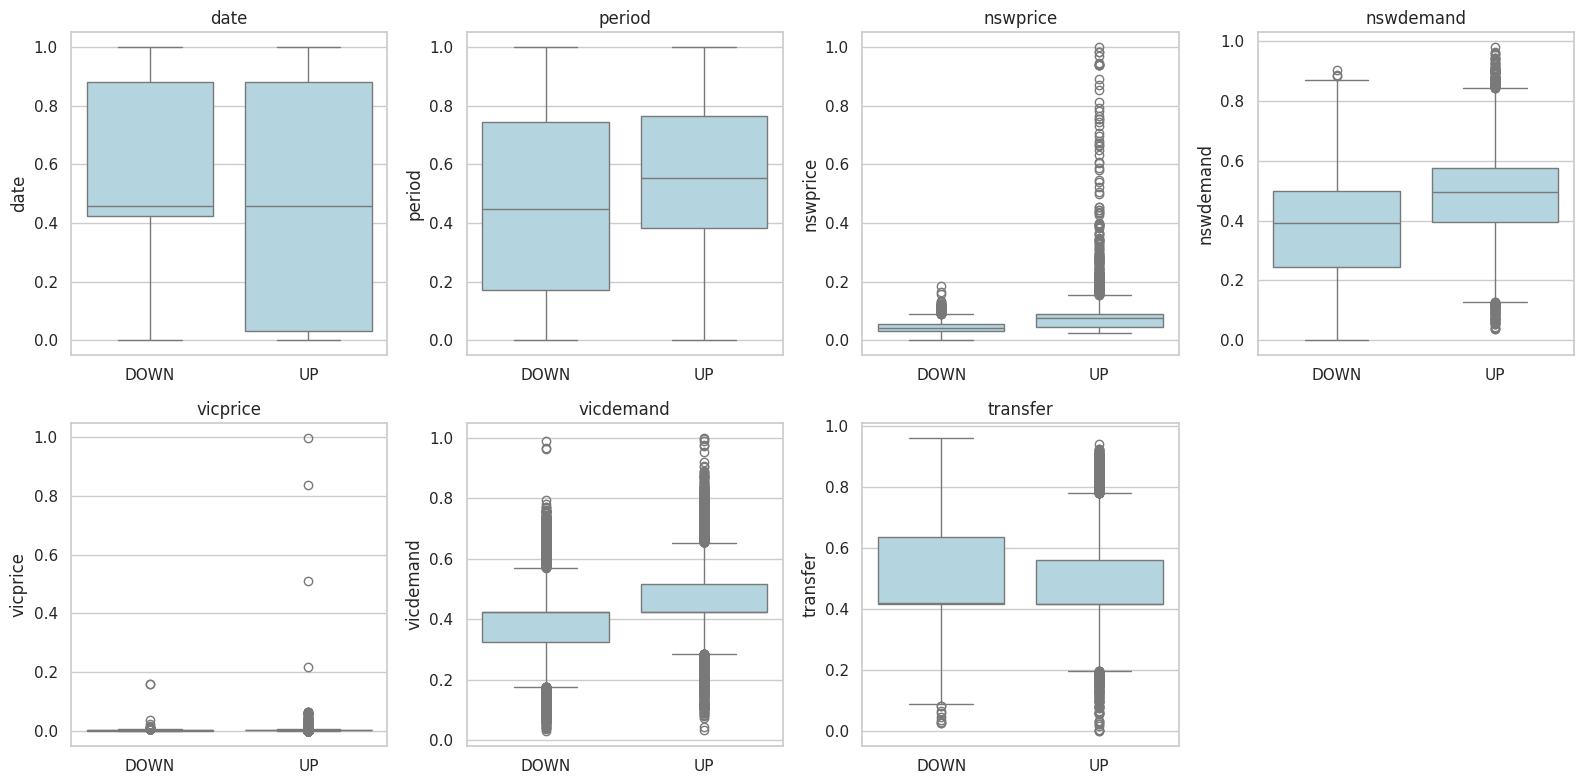

In [19]:
group_means = eda.groupby("class", observed=True)[numeric_features].mean().round(4)
display(group_means)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.flat, numeric_features):
    sns.boxplot(data=eda, x="class", y=column, order=["DOWN", "UP"], color="lightblue", ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

UP observations have higher average normalised NSW price and demand than DOWN observations. Average
NSW price is 0.0763 for UP and 0.0447 for DOWN. Average NSW demand is 0.4899 for UP and
0.3792 for DOWN.

The groups overlap, so these differences do not provide a perfect classification rule or prove
performance on unseen data. NSW price is also closely related to how the target is defined.

### 3.6 Demand and Transfer Distributions by Class

Density plots show smoothed distributions of NSW demand, Victoria demand and transfer for UP and DOWN
observations. Each class curve is scaled separately so we can compare shapes.

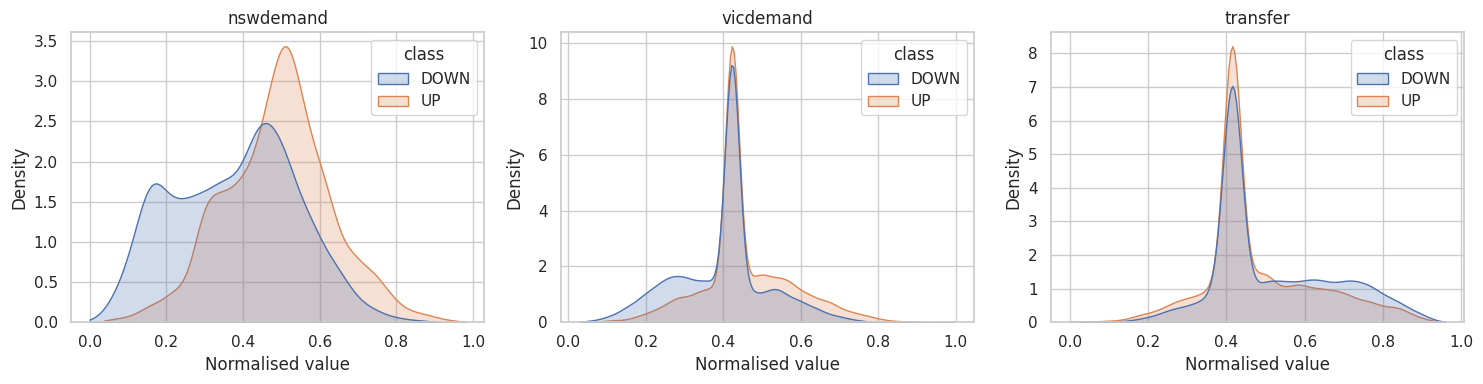

In [20]:
features_to_plot = ["nswdemand", "vicdemand", "transfer"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, features_to_plot):
    sns.kdeplot(data=eda, x=column, hue="class", hue_order=["DOWN", "UP"],
                common_norm=False,   # scale each class separately to compare shapes
                fill=True, cut=0,    # do not extend curves beyond the observed range
                ax=ax)
    ax.set_title(column)
    ax.set_xlabel("Normalised value")
plt.tight_layout()
plt.show()

The curves show where values are concentrated within each class. Differences may suggest useful
information for classification, but they do not prove that a reliable prediction rule exists. These
curves are smoothed estimates, so use the histograms as well when checking sharp peaks.

### 3.7 Relationship Between NSW and Victoria Demand

The scatter plot compares NSW demand with Victoria demand, coloured by UP or DOWN. A fixed random
sample of 5,000 training observations keeps the chart readable.

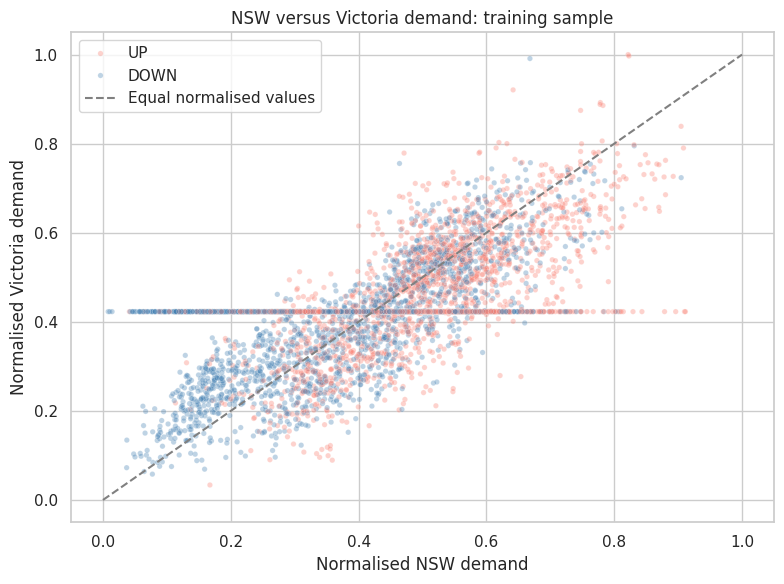

In [21]:
sample = eda.sample(n=min(5000, len(eda)), random_state=SEED)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="nswdemand", y="vicdemand", hue="class",
                palette={"DOWN": "steelblue", "UP": "salmon"}, alpha=0.35, s=15)
# The diagonal marks equal normalised values, not equal demand in megawatts.
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Equal normalised values")
plt.title("NSW versus Victoria demand: training sample")
plt.xlabel("Normalised NSW demand")
plt.ylabel("Normalised Victoria demand")
plt.legend()
plt.tight_layout()
plt.show()

The plot helps us see whether the demand measurements vary together and whether UP and DOWN
observations occupy different areas. The dashed line marks equal normalised values, not equal demand
in megawatts.

### 3.8 Day-of-Week and Target-Class Distribution

We count UP and DOWN observations for each day-of-week code and calculate percentages within each day
code so they can be compared.

class,DOWN,UP
day,,
0,1501,1884
1,1565,1773
2,1684,1570
3,1642,1610
4,1733,1587
5,1724,1519
6,1654,1638


class,DOWN,UP
day,,
0,44.34,55.66
1,46.88,53.12
2,51.75,48.25
3,50.49,49.51
4,52.20,47.80
5,53.16,46.84
6,50.24,49.76


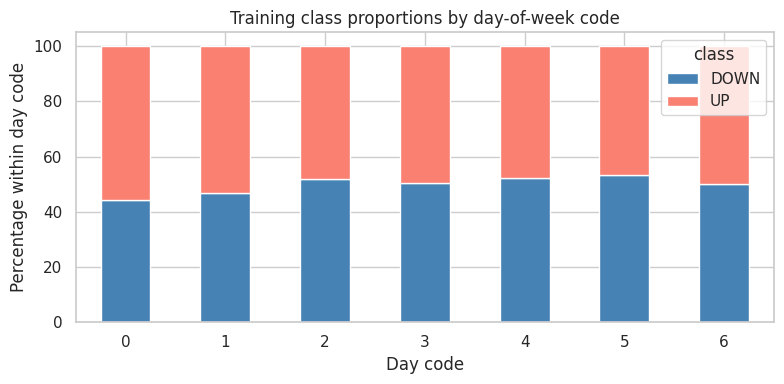

In [22]:
day_counts = pd.crosstab(eda["day"], eda["class"]).reindex(columns=["DOWN", "UP"], fill_value=0)
day_percent = day_counts.div(day_counts.sum(axis=1), axis=0) * 100

display(day_counts)
display(day_percent.round(2))

day_percent.plot(kind="bar", stacked=True, figsize=(8, 4), color=["steelblue", "salmon"])
plt.title("Training class proportions by day-of-week code")
plt.xlabel("Day code")
plt.ylabel("Percentage within day code")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The percentage of UP observations varies across day codes, from 55.66 % for day code
0 to 46.84 % for day code 5. These differences may help classification.
They describe this training sample and do not prove that the day itself causes a price change.

### 3.9 Within-Day Patterns

We compare average NSW and Victoria demand across the half-hour periods within a day, and the
proportion of UP labels at each period.

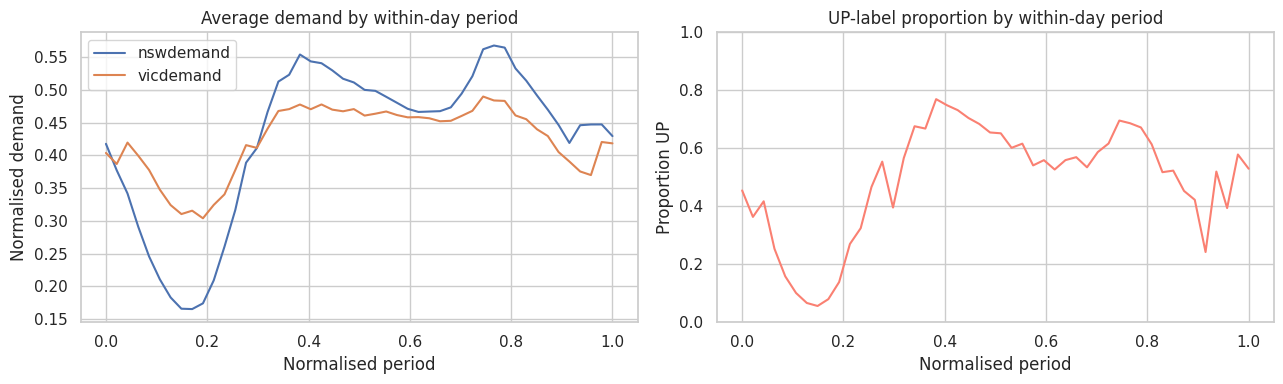

In [23]:
# Since target is 0/1, its mean equals the proportion labelled UP.
period_summary = eda.groupby("period")[["nswdemand", "vicdemand", "target"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
period_summary[["nswdemand", "vicdemand"]].plot(ax=axes[0])
axes[0].set_title("Average demand by within-day period")
axes[0].set_xlabel("Normalised period")
axes[0].set_ylabel("Normalised demand")

period_summary["target"].plot(ax=axes[1], color="salmon")
axes[1].set_title("UP-label proportion by within-day period")
axes[1].set_xlabel("Normalised period")
axes[1].set_ylabel("Proportion UP")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

The plots show how average demand and the frequency of UP labels vary across the day. Because UP is
coded as 1 and DOWN as 0, the average target value equals the proportion of UP observations. The
horizontal axis shows normalised period values rather than clock times.

### 3.10 Correlation Analysis

The heatmap shows linear relationships between numerical features and the target, from -1 to +1.
Day-of-week codes are excluded because they represent categories.

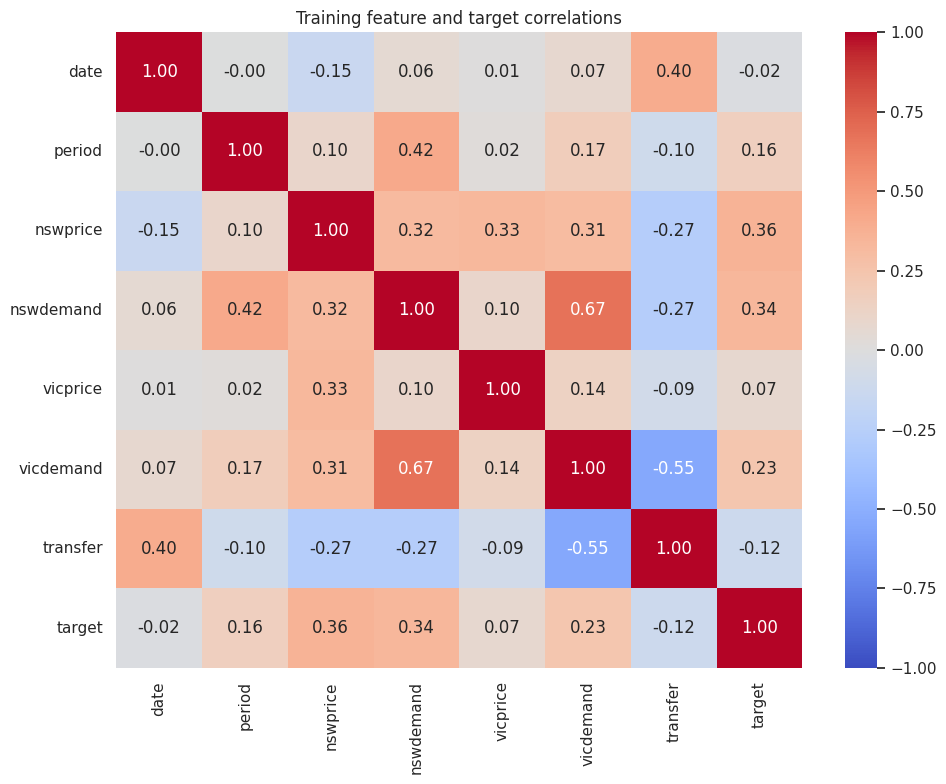

,Correlation with UP target
transfer,-0.122542
date,-0.018942
vicprice,0.071723
period,0.157501
vicdemand,0.234949
nswdemand,0.341973
nswprice,0.362154


In [24]:
correlations = eda[numeric_features + ["target"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Training feature and target correlations")
plt.tight_layout()
plt.show()

display(correlations["target"].drop("target").sort_values().to_frame("Correlation with UP target"))

NSW price has the strongest positive correlation with the UP target (0.362), followed by
nswdemand (0.342). NSW demand has a correlation of 0.342 and transfer has a
correlation of -0.123.

Correlation does not prove causation, and a weak linear correlation does not rule out useful nonlinear
relationships. Such nonlinear combinations of columns are exactly what OCTree's generated features
try to capture.

### 3.11 Patterns Over Time

We examine changes in average demand and the proportion of UP labels across the time span of the
training data. Observations are grouped by `date` (approximately one value per day), and a rolling
average over 7 consecutive days (about one week) smooths the daily values. The horizontal axis
shows each day's position in time order, because the normalised `date` values are not evenly spaced in time.

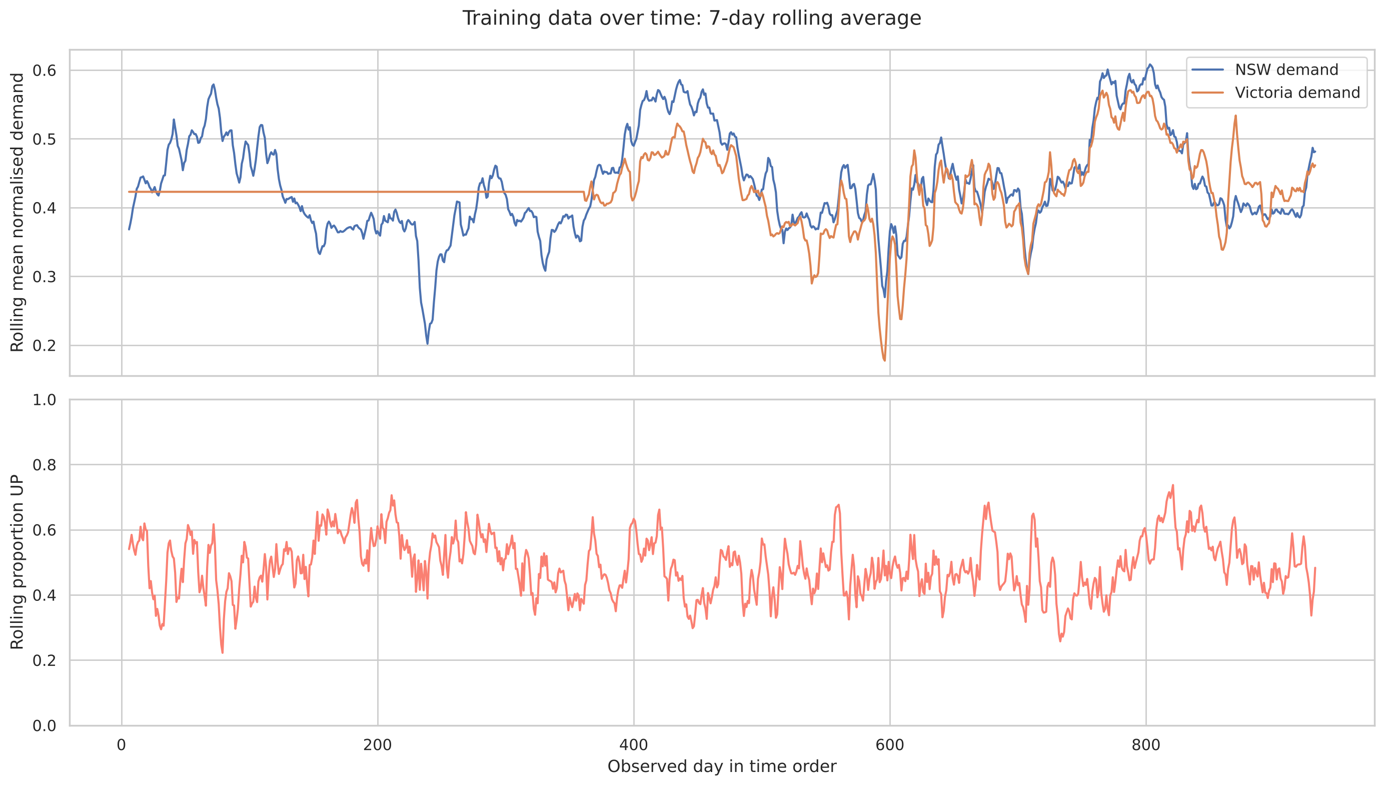

In [25]:
# Daily averages in time order, then a rolling 7-day average (about one week).
# The x-axis is the day's position in time order (1st, 2nd, ... observed day), because the
# normalised 'date' values are not evenly spaced in time and would leave large empty gaps.
daily = eda.groupby("date")[["nswdemand", "vicdemand", "target"]].mean().sort_index()
daily = daily.reset_index(drop=True)                 # 0, 1, 2, ... = day position in time order
rolling = daily.rolling(window=7, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(rolling.index, rolling["nswdemand"], label="NSW demand")
axes[0].plot(rolling.index, rolling["vicdemand"], label="Victoria demand")
axes[0].set_ylabel("Rolling mean normalised demand")
axes[0].legend()

axes[1].plot(rolling.index, rolling["target"], color="salmon")
axes[1].set_ylabel("Rolling proportion UP")
axes[1].set_xlabel("Observed day in time order")
axes[1].set_ylim(0, 1)

plt.suptitle("Training data over time: 7-day rolling average")
plt.tight_layout()
plt.show()

The plots show how average demand and the share of UP labels change over the period covered by the
data. Because `date` is normalised and a few `date` values cover two days, the horizontal axis is an
approximate time line, not exact calendar dates.

Changes in these averages do not by themselves prove concept drift, which means a change in the
relationship between inputs and target.

### 3.12 Summary of Findings and Limitations

The dataset (OpenML 44156) contains 38,474 observations with no missing values. Following the paper,
each of three random seeds splits it into 23,084 training, 7,695 validation and 7,695 test
observations, and every feature is min-max scaled using training data only. The processed inputs have
eight columns, renamed `x1 … x8`, with no missing or infinite values.

The classes are balanced: the seed-0 training data contains 49.83 % DOWN and 50.17 %
UP observations, so a constant prediction scores about 50 %.

UP observations have higher average normalised NSW price and demand. NSW price has the strongest
positive linear correlation with the target (0.362).

These findings describe the training data. They do not establish causation or show how well a model
performs on unseen observations.

**Limitations.** The data was already normalised by its source. This benchmark version is shuffled and
balanced by removing DOWN rows, so its time order can only be rebuilt approximately. Random splits put
closely related neighbouring half-hours into different groups, which can make scores look better than
on genuinely new days. The task classifies current
observations, so including current NSW price does not demonstrate prediction of a future price.

### 3.13 Planned Experiments and Evaluation Metrics

We will compare three versions of the inputs:
1. Original features (`x1 … x8`).
2. Original features plus the starting rule (product of the two most important columns).
3. Original features plus OCTree-generated features.

All comparisons use the same three random splits; results are averaged over seeds 0, 1 and 2.

**Metrics**

- **Error rate / accuracy:** the main metric in the paper. The classes are balanced, so accuracy is a
  fair measure; a constant prediction scores about 50 %.
- **Precision, recall and F1 (for UP):** show how well UP observations are found and how reliable UP
  predictions are.
- **Balanced accuracy:** the average of recall on each class.
- **ROC-AUC:** ranking quality across all thresholds, independent of the 0.5 cut-off.
- **Confusion matrix:** the exact mix of false UP and false DOWN predictions.

Training and validation data support feature and model selection. Test results are reserved for the
final evaluation and are never used as feedback to OCTree.

### 3.14 Sources

- OpenML Electricity dataset, ID 44156 (benchmark version used in the paper): https://www.openml.org/d/44156
- Original OpenML Electricity dataset, ID 151: https://www.openml.org/d/151
- Harries, M. (1999). *Splice-2 comparative evaluation: Electricity pricing*. University of New South Wales.
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep
  learning on typical tabular data? *NeurIPS 35*.
- Nam, J., Kim, K., Oh, S., Tack, J., Kim, J., & Shin, J. (2024). Optimized feature generation for
  tabular data via LLMs with decision tree reasoning. *NeurIPS 37*.
- Official OCTree code: https://github.com/jaehyun513/OCTree